# F4 · Sensibilidad de la lectura conjunta a Antofagasta

**Proyecto MCDI500 · Grupo 7 · Aporte de Pavel** · Issue #58

Antofagasta tiene la mayor frecuencia documental de las 15 comunas (45,6 informes por 100.000 hab.-año, casi el doble que Arica) y es la única que se distingue con claridad del resto (Figura 506). El punto 3 de la retroalimentación de F3 pide revisar **por qué domina** y **cuánto pesa** en la lectura conjunta:

| Pregunta | Qué se mide | Código |
|---|---|---|
| **1. ¿Depende de pocas instalaciones?** | Qué parte de los informes de cada comuna viene de sus cinco subestaciones y sus cinco empresas más frecuentes | `concentracion_por_comuna()` |
| **2. ¿Depende de un período acotado?** | Frecuencia anualizada y puesto de cada comuna en 2024, 2025 y 2026 | `informes_por_anio()` |
| **3. ¿Domina la lectura de las 15 comunas?** | Indicadores agregados con y sin Antofagasta | `resumen_con_y_sin()` |

Las funciones viven en `src/sensibilidad.py` y tienen pruebas en `tests/test_sensibilidad.py`. Este notebook no vuelve a procesar los datos: parte de los artefactos de F2 y F3 y escribe solo sus propias salidas (Figura 508 y tablas 409 a 411).

**Cómo leer este notebook.** Un *informe* es un documento de falla publicado por el CEN. Un *vínculo* une un informe con una comuna; un informe que nombra dos comunas genera dos vínculos. Las cifras son **descriptivas**: dicen con qué frecuencia algo *aparece en los informes*, no por qué ocurre ni cuántas personas quedaron sin suministro.

## 1. Carga y verificación de los datos

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src.sensibilidad import (concentracion_por_comuna, informes_por_anio,
                              no_anulados, resumen_con_y_sin, unir_instalaciones)
from src.temporal import contar_informes_mensuales

COMUNA = "Antofagasta"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_RESULTADOS = RAIZ / "F4" / "resultados"
FUENTE = ("Fuente: elaboración propia con informes de falla del Coordinador Eléctrico "
          "Nacional (CEN, ene-2024 a sep-2026) y población del Censo 2024 (INE).")

asociaciones = pd.read_csv(
    RAIZ / "data" / "processed" / "f2" / "04_cen_fallas_comunas_integrado.csv",
    low_memory=False, dtype={"codigo_comuna": str})
panel = pd.read_csv(RAIZ / "F3" / "resultados" / "F3_701_Panel_Integrado_Comunal.csv",
                    dtype={"codigo_comuna": str})
# El consolidado del CEN aporta la subestación y la empresa de cada informe.
eventos = pd.read_csv(RAIZ / "data" / "processed" / "cen_fallas_2024_2026_eventos.csv",
                      low_memory=False, usecols=["id_falla", "SubEstación", "Empresa"])

validas = no_anulados(asociaciones)
datos = unir_instalaciones(validas, eventos)

assert len(asociaciones) == 1915 and len(panel) == 15, "Los artefactos de F2 y F3 cambiaron."
assert len(validas) == int(panel["informes_no_anulados"].sum()), \
    "Los vínculos no anulados no cuadran con el panel de F3."
assert datos["Empresa"].notna().all(), "Hay informes sin empresa en el consolidado."

print(f"Vínculos no anulados: {len(validas):,} · informes únicos: {validas['id_falla'].nunique():,}"
      f" · comunas: {len(panel)}")
print(f"{COMUNA}: {int(panel.set_index('comuna_oficial').loc[COMUNA, 'informes_no_anulados'])} "
      f"informes no anulados, {panel.set_index('comuna_oficial').loc[COMUNA, 'poblacion_2024']:,.0f} habitantes")

Vínculos no anulados: 1,784 · informes únicos: 1,704 · comunas: 15
Antofagasta: 503 informes no anulados, 401,096 habitantes


## 2. ¿Depende de pocas instalaciones?

Si unos pocos equipos explicaran la frecuencia de Antofagasta, sus informes se concentrarían en pocas subestaciones o pocas empresas. Se mide, para cada comuna, qué porcentaje de sus informes viene de las **cinco subestaciones** y las **cinco empresas** más frecuentes. Las fallas de línea o de central no tienen subestación, así que el porcentaje de subestaciones se calcula sobre los informes que la registran.

In [2]:
subestaciones = concentracion_por_comuna(datos, "SubEstación", top=5)
empresas = concentracion_por_comuna(datos, "Empresa", top=5)

concentracion = (
    subestaciones.rename(columns={"informes_con_dato": "informes_con_subestacion",
                                  "distintos": "subestaciones_distintas",
                                  "principal": "subestacion_principal",
                                  "pct_principal": "pct_subestacion_principal",
                                  "pct_top5": "pct_top5_subestaciones"})
    .merge(empresas[["comuna_oficial", "distintos", "pct_principal", "pct_top5"]]
           .rename(columns={"distintos": "empresas_distintas",
                            "pct_principal": "pct_empresa_principal",
                            "pct_top5": "pct_top5_empresas"}),
           on="comuna_oficial", validate="one_to_one")
    .sort_values("pct_top5_subestaciones", ascending=False, kind="mergesort")
    .reset_index(drop=True)
)
concentracion.to_csv(DIR_RESULTADOS / "F4_Tabla_409_Concentracion_Instalaciones.csv",
                     index=False, encoding="utf-8-sig", lineterminator="\n")

fila = concentracion.set_index("comuna_oficial").loc[COMUNA]
resto = concentracion.loc[concentracion["comuna_oficial"].ne(COMUNA)]
print(f"{COMUNA}: {fila['subestaciones_distintas']} subestaciones y {fila['empresas_distintas']} empresas; "
      f"las 5 más frecuentes reúnen {fila['pct_top5_subestaciones']} % y {fila['pct_top5_empresas']} %.")
print(f"Resto de las comunas: {resto['pct_top5_subestaciones'].min()} % a "
      f"{resto['pct_top5_subestaciones'].max()} % (subestaciones) y "
      f"{resto['pct_top5_empresas'].min()} % a {resto['pct_top5_empresas'].max()} % (empresas).")
concentracion

Antofagasta: 85 subestaciones y 51 empresas; las 5 más frecuentes reúnen 46.5 % y 59.0 %.
Resto de las comunas: 51.3 % a 90.9 % (subestaciones) y 76.7 % a 100.0 % (empresas).


,comuna_oficial,informes,informes_con_subestacion,subestaciones_distintas,subestacion_principal,pct_subestacion_principal,pct_top5_subestaciones,empresas_distintas,pct_empresa_principal,pct_top5_empresas
0,Viña del Mar,67,55,9,S/E MIRAFLORES,43.6,90.9,5,25.4,100.0
1,La Serena,101,79,8,S/E MARQUESA,25.3,89.9,9,28.7,96.0
2,La Florida,82,35,8,S/E FLORIDA,34.3,88.6,7,50.0,93.9
3,Arica,161,120,11,S/E PUKARA,28.3,86.7,10,32.3,96.3
4,Puerto Montt,54,42,11,S/E MELIPULLI,59.5,83.3,7,35.2,96.3
5,San Bernardo,72,53,13,S/E MARISCAL,30.2,83.0,9,45.8,91.7
6,Puente Alto,150,87,12,S/E PUENTE ALTO (TEC),20.7,77.0,12,22.7,78.0
7,Rancagua,141,74,13,S/E PUNTA DE CORTES,23.0,75.7,10,32.6,95.0
8,Temuco,101,68,14,S/E CHIVILCAN,20.6,75.0,8,42.6,94.1
9,Las Condes,35,29,13,S/E VITACURA,31.0,72.4,4,40.0,100.0


In [3]:
# La descripción que más aparece en Antofagasta, ¿viene de pocas empresas?
terceros = datos.loc[
    datos["comuna_oficial"].eq(COMUNA)
    & datos["descripcion_causa"].eq("Desconexión debido a falla en instalaciones de terceros.")
]
empresas_terceros = concentracion_por_comuna(terceros, "Empresa", top=3).iloc[0]
print(f"Informes de {COMUNA} con «falla en instalaciones de terceros»: {empresas_terceros['informes']}")
print(f"Empresas que los informan: {empresas_terceros['distintos']}; "
      f"las 3 más frecuentes reúnen {empresas_terceros['pct_top3']} % "
      f"(la principal, {empresas_terceros['principal']}: {empresas_terceros['pct_principal']} %).")

Informes de Antofagasta con «falla en instalaciones de terceros»: 110
Empresas que los informan: 25; las 3 más frecuentes reúnen 36.4 % (la principal, CGE TRANSMISIÓN S.A.: 20.9 %).


### 2.1. Lectura

Antofagasta es la comuna **menos concentrada** de las 15: sus informes provienen de 85 subestaciones y 51 empresas, y las cinco más frecuentes reúnen el 46,5 % y el 59,0 %. En las demás comunas, las cinco subestaciones más frecuentes reúnen entre el 51,3 % y el 90,9 %, y las cinco empresas, entre el 76,7 % y el 100 %. La frecuencia de Antofagasta **no se explica por unas pocas instalaciones**: se reparte en una red amplia de instalaciones y empresas.

Lo mismo ocurre con la descripción que más aparece en la comuna, «falla en instalaciones de terceros»: sus 110 informes provienen de 25 empresas, y la principal reúne el 20,9 %.

*Límite:* el CEN registra la subestación y la empresa que informan la falla, no necesariamente el equipo que la originó.

## 3. ¿Depende de un período acotado?

Si un episodio explicara la frecuencia de Antofagasta, la comuna destacaría en un año y no en los otros. Se calcula la frecuencia de cada año, **anualizada** con los meses observados (2026 tiene nueve meses), y el puesto de cada comuna.

In [4]:
anual = informes_por_anio(validas, panel)
anual.to_csv(DIR_RESULTADOS / "F4_Tabla_410_Frecuencia_Anual.csv",
             index=False, encoding="utf-8-sig", lineterminator="\n")

# Matriz comuna × mes de src/temporal.py (Figura 505): ¿en cuántos meses encabeza?
matriz = contar_informes_mensuales(asociaciones)
meses_primera = int((matriz.idxmax() == COMUNA).sum())

tabla_anual = anual.pivot(index="comuna_oficial", columns="anio", values="frecuencia_100k_hab_anio")
puestos = anual.loc[anual["comuna_oficial"].eq(COMUNA)].set_index("anio")
print(f"{COMUNA} por año (puesto entre 15):")
print(puestos[["informes", "meses_observados", "frecuencia_100k_hab_anio", "puesto"]].to_string())
print(f"\n{COMUNA} tiene más informes que cualquier otra comuna en {meses_primera} de {matriz.shape[1]} meses.")
print(f"Segunda comuna de cada año: " + ", ".join(
    f"{a}: {anual.loc[(anual['anio'] == a) & (anual['puesto'] == 2), 'comuna_oficial'].item()}"
    for a in sorted(anual['anio'].unique())))
tabla_anual.sort_values(2025, ascending=False)

Antofagasta por año (puesto entre 15):
      informes  meses_observados  frecuencia_100k_hab_anio  puesto
anio                                                              
2024       166                12                     41.39       1
2025       207                12                     51.61       1
2026       130                 9                     43.21       1

Antofagasta tiene más informes que cualquier otra comuna en 21 de 33 meses.
Segunda comuna de cada año: 2024: Rancagua, 2025: Arica, 2026: Arica


anio,2024,2025,2026
comuna_oficial,,,
Antofagasta,41.39,51.61,43.21
Arica,10.35,39.73,22.07
Rancagua,14.36,30.65,12.93
Coquimbo,11.00,23.51,14.66
La Serena,10.79,15.19,19.19
Temuco,12.99,14.70,9.12
Valparaíso,12.28,13.34,11.23
San Bernardo,6.53,12.08,6.53
Puente Alto,7.04,10.74,11.50


### 3.1. Lectura

Antofagasta es **primera en los tres años**: 41,4 informes por 100.000 hab.-año en 2024, 51,6 en 2025 y 43,2 entre enero y septiembre de 2026. Además, tiene más informes que cualquier otra comuna en 21 de los 33 meses. La segunda posición, en cambio, la ocupa Rancagua en 2024 y Arica en 2025 y 2026. El patrón de Antofagasta **es persistente** y no depende de un período acotado. El apagón del 25-02-2025 tampoco lo explica: sin ese día, Antofagasta sigue primera (39,4; Tabla 406).

## 4. Figura 508

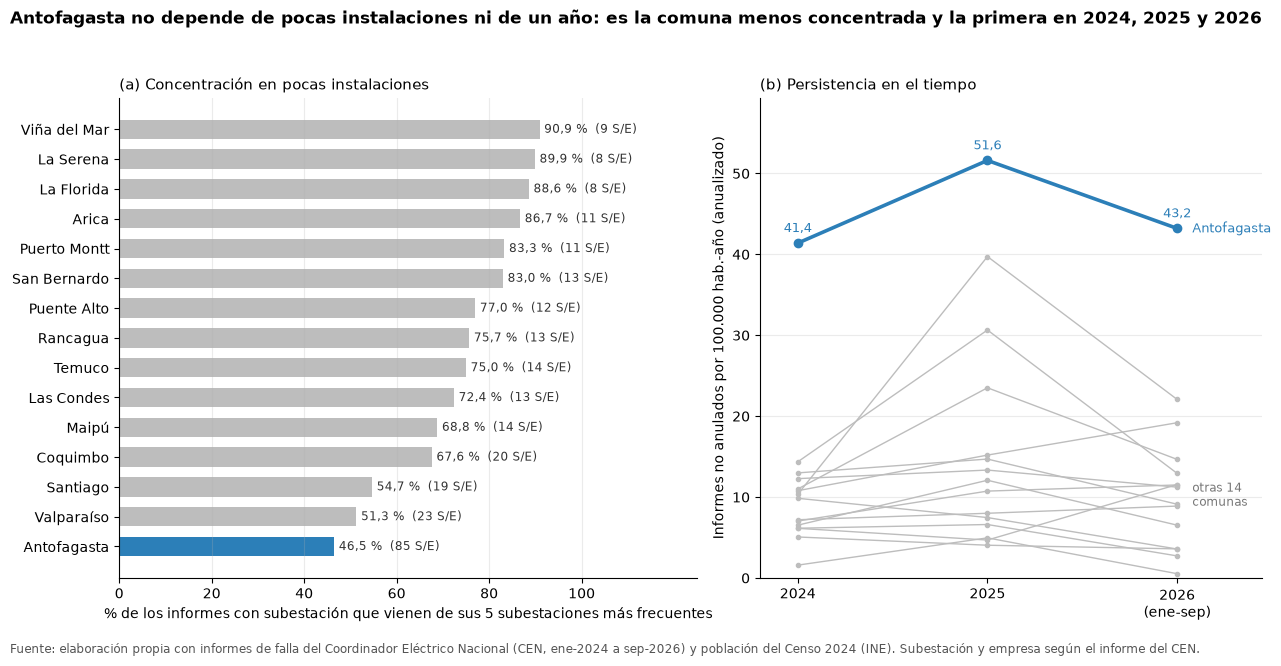

In [5]:
def coma(valor, decimales=1):
    return f"{valor:.{decimales}f}".replace(".", ",")


AZUL, GRIS = "#2c7fb8", "#bdbdbd"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.6), gridspec_kw={"width_ratios": [1.15, 1]})

# (a) Concentración: barras horizontales ordenadas.
orden = concentracion.sort_values("pct_top5_subestaciones")
y = range(len(orden))
colores = [AZUL if c == COMUNA else GRIS for c in orden["comuna_oficial"]]
ax1.barh(list(y), orden["pct_top5_subestaciones"], color=colores, height=0.65)
for i, (_, f) in enumerate(orden.iterrows()):
    ax1.text(f["pct_top5_subestaciones"] + 1, i,
             f"{coma(f['pct_top5_subestaciones'])} %  ({f['subestaciones_distintas']} S/E)",
             va="center", fontsize=8.5, color="#333333")
ax1.set_yticks(list(y))
ax1.set_yticklabels(orden["comuna_oficial"])
ax1.set_xlim(0, 125)
ax1.set_xticks(range(0, 101, 20))
ax1.set_xlabel("% de los informes con subestación que vienen de sus 5 subestaciones más frecuentes")
ax1.set_title("(a) Concentración en pocas instalaciones", loc="left", fontsize=10.5)

# (b) Persistencia: frecuencia anualizada por año.
for comuna, serie in tabla_anual.iterrows():
    destacada = comuna == COMUNA
    ax2.plot(serie.index, serie.values, marker="o", color=AZUL if destacada else GRIS,
             linewidth=2.6 if destacada else 1, markersize=6 if destacada else 3,
             zorder=3 if destacada else 2)
for anio, valor in tabla_anual.loc[COMUNA].items():
    ax2.annotate(coma(valor), (anio, valor), textcoords="offset points", xytext=(0, 8),
                 ha="center", fontsize=9, color=AZUL)
ax2.text(2026.08, tabla_anual.loc[COMUNA, 2026], COMUNA, color=AZUL, va="center", fontsize=9)
ax2.text(2026.08, tabla_anual.drop(COMUNA)[2026].median(), "otras 14\ncomunas",
         color="#777777", va="center", fontsize=8.5)
ax2.set_xticks([2024, 2025, 2026])
ax2.set_xticklabels(["2024", "2025", "2026\n(ene-sep)"])
ax2.set_xlim(2023.8, 2026.45)
ax2.set_ylim(0, tabla_anual.max().max() * 1.15)
ax2.set_ylabel("Informes no anulados por 100.000 hab.-año (anualizado)")
ax2.set_title("(b) Persistencia en el tiempo", loc="left", fontsize=10.5)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="x", alpha=0.25)
ax2.grid(axis="y", alpha=0.25)

fig.suptitle("Antofagasta no depende de pocas instalaciones ni de un año: es la comuna menos "
             "concentrada y la primera en 2024, 2025 y 2026", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold")
fig.text(0.01, 0.005, FUENTE + " Subestación y empresa según el informe del CEN.",
         fontsize=8.5, color="#555555")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(DIR_FIGURAS / "F4_Figura_508_Sensibilidad_Antofagasta.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. ¿Domina la lectura de las 15 comunas? Panel con y sin Antofagasta

Se calculan los indicadores del conjunto con y sin la comuna. Si cambian mucho, la lectura conjunta debe presentarse de las dos formas.

In [6]:
con_sin = resumen_con_y_sin(asociaciones, panel, COMUNA)
con_sin.to_csv(DIR_RESULTADOS / "F4_Tabla_411_Panel_Con_Sin_Antofagasta.csv",
               index=False, encoding="utf-8-sig", lineterminator="\n")

poblacion = panel.set_index("comuna_oficial")["poblacion_2024"]
vinculos = panel.set_index("comuna_oficial")["informes_no_anulados"]
pct_poblacion = 100 * poblacion[COMUNA] / poblacion.sum()
pct_vinculos = 100 * vinculos[COMUNA] / vinculos.sum()
fila_f = con_sin.set_index("indicador").loc["Frecuencia agregada (vínculos por 100.000 hab.-año)"]
caida = 100 * (1 - fila_f.iloc[1] / fila_f.iloc[0])

print(f"{COMUNA}: {coma(pct_poblacion)} % de la población y {coma(pct_vinculos)} % de los vínculos no anulados.")
print(f"Sin {COMUNA}, la frecuencia agregada baja un {coma(caida)} %.")
con_sin

Antofagasta: 7,9 % de la población y 28,2 % de los vínculos no anulados.
Sin Antofagasta, la frecuencia agregada baja un 22,1 %.


,indicador,15 comunas,sin Antofagasta
0,Comunas,15,14
1,Población 2024,5091638,4690542
2,Informes únicos no anulados,1704,1201
3,Vínculos informe-comuna no anulados,1784,1281
4,Frecuencia agregada (vínculos por 100.000 hab....,12.74,9.93
5,Promedio de las frecuencias comunales,13.24,10.93
6,Descripción causal determinada más frecuente,Desconexión debido a falla en instalaciones de...,Desconexión debido a falla en instalaciones de...
7,Participación de esa descripción (% de informe...,13.25,9.71
8,Intervalos documentales elegibles (informes ún...,954,647
9,Mediana del intervalo documental (horas),1.6,1.38


### 5.1. Lectura

Antofagasta reúne el 7,9 % de la población de las 15 comunas, pero el 28,2 % de los vínculos no anulados. Sin ella:

- la frecuencia agregada baja de 12,74 a 9,93 vínculos por 100.000 hab.-año (−22,1 %), y el promedio de las frecuencias comunales, de 13,24 a 10,93;
- la descripción causal determinada más frecuente **sigue siendo la misma**, «falla en instalaciones de terceros», pero su participación baja del 13,25 % al 9,71 % de los informes;
- la mediana del intervalo documental baja de 1,60 a 1,38 horas.

**Consecuencia para el informe y el video:** cuando se hable del conjunto de las 15 comunas, se debe dar también la cifra sin Antofagasta, porque una sola comuna mueve la frecuencia agregada en más de una quinta parte. Las comparaciones entre las otras comunas no cambian, porque cada frecuencia comunal se calcula por separado.

## 6. Hallazgos para el informe y el video

| Hallazgo | Cifra | Celda |
|---|---|---|
| Antofagasta no depende de pocas instalaciones | 85 subestaciones y 51 empresas; las 5 más frecuentes reúnen el 46,5 % y el 59,0 % (la menor concentración de las 15) | §2 |
| El patrón es persistente | Primera en 2024 (41,4), 2025 (51,6) y 2026 (43,2); más informes que cualquier otra comuna en 21 de 33 meses | §3 |
| Antofagasta pesa en la lectura conjunta | 7,9 % de la población y 28,2 % de los vínculos; sin ella, la frecuencia agregada baja de 12,74 a 9,93 (−22,1 %) | §5 |
| La descripción más frecuente no cambia sin Antofagasta | «Falla en instalaciones de terceros»: del 13,25 % al 9,71 % de los informes | §5 |

## 7. Verificación final de productos y cifras citadas

In [7]:
productos = [
    DIR_FIGURAS / "F4_Figura_508_Sensibilidad_Antofagasta.png",
    DIR_RESULTADOS / "F4_Tabla_409_Concentracion_Instalaciones.csv",
    DIR_RESULTADOS / "F4_Tabla_410_Frecuencia_Anual.csv",
    DIR_RESULTADOS / "F4_Tabla_411_Panel_Con_Sin_Antofagasta.csv",
]
for ruta in productos:
    assert ruta.exists() and ruta.stat().st_size > 0, f"Falta {ruta.name}"
    print(f"[OK] {ruta.relative_to(RAIZ)}")

# Las cifras de las lecturas (§2.1, §3.1, §5.1 y §6) salen de estos cálculos.
c = concentracion.set_index("comuna_oficial")
assert (c.loc[COMUNA, "subestaciones_distintas"], c.loc[COMUNA, "empresas_distintas"]) == (85, 51)
assert (c.loc[COMUNA, "pct_top5_subestaciones"], c.loc[COMUNA, "pct_top5_empresas"]) == (46.5, 59.0)
assert c["pct_top5_subestaciones"].idxmin() == COMUNA and c["pct_top5_empresas"].idxmin() == COMUNA
assert (resto["pct_top5_subestaciones"].min(), resto["pct_top5_subestaciones"].max()) == (51.3, 90.9)
assert (resto["pct_top5_empresas"].min(), resto["pct_top5_empresas"].max()) == (76.7, 100.0)
assert (empresas_terceros["informes"], empresas_terceros["distintos"], empresas_terceros["pct_principal"]) == (110, 25, 20.9)
assert puestos["puesto"].eq(1).all()
assert puestos["frecuencia_100k_hab_anio"].tolist() == [41.39, 51.61, 43.21]
assert meses_primera == 21
assert round(pct_poblacion, 1) == 7.9 and round(pct_vinculos, 1) == 28.2 and round(caida, 1) == 22.1
r = con_sin.set_index("indicador")
assert r.loc["Frecuencia agregada (vínculos por 100.000 hab.-año)"].tolist() == [12.74, 9.93]
assert r.loc["Promedio de las frecuencias comunales"].tolist() == [13.24, 10.93]
assert r.loc["Descripción causal determinada más frecuente"].nunique() == 1
assert r.loc["Participación de esa descripción (% de informes únicos)"].tolist() == [13.25, 9.71]
assert r.loc["Mediana del intervalo documental (horas)"].tolist() == [1.6, 1.38]
print("[OK] Las cifras citadas en las lecturas coinciden con los cálculos.")

[OK] F4/figuras/F4_Figura_508_Sensibilidad_Antofagasta.png
[OK] F4/resultados/F4_Tabla_409_Concentracion_Instalaciones.csv
[OK] F4/resultados/F4_Tabla_410_Frecuencia_Anual.csv
[OK] F4/resultados/F4_Tabla_411_Panel_Con_Sin_Antofagasta.csv
[OK] Las cifras citadas en las lecturas coinciden con los cálculos.
